In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import pandas as pd
import scipy
from scipy.stats import ttest_ind
import seaborn as sns
from math import sqrt
import re
from matplotlib.ticker import ScalarFormatter
import matplotlib.ticker as mticker
from itertools import product

cell_types = ["Exc", "Pvalb", "Sst", "Vip", "Htr3a"]
layers = ["L1", "L2/3", "L4", "L5", "L6"]
colors = [
    "tab:red",
    "tab:blue",
    "tab:green",
    "tab:purple",
    "tab:purple",
]

In [2]:
net_name = "core"  # change to "core_<variant>" for a model variant
power_layers = pd.read_csv(f"{net_name}/metrics/other_visual_stim_power/other_visual_stim_all_dirs_mua_power_layer.csv")
power_pop_name = pd.read_csv(f"{net_name}/metrics/other_visual_stim_power/other_visual_stim_all_dirs_mua_power.csv")

In [3]:
def str2list(str_time):
    str_time = str_time[1:-1]
    array_list = str_time.strip(",").split(", ")
    return np.stack([float(ii) for ii in array_list])

In [4]:
power_layers["power"] = power_layers["power"].apply(str2list)
power_layers["f"] = power_layers["f"].apply(str2list)

power_pop_name["power"] = power_pop_name["power"].apply(str2list)
power_pop_name["f"] = power_pop_name["f"].apply(str2list)

In [5]:
power_pop_name.condition.unique()

array(['drifting grating', 'natural scenes', 'natural movie one',
       'natural movie two'], dtype=object)

In [6]:
power_layers_df = power_layers.groupby(["condition", "layer"]).agg(
    {
        "power": list,
        "f": list,
    }
)
power_layers_df.reset_index(inplace=True)
power_layers_df["mean"] = power_layers_df["power"].apply(np.mean, axis=0)
power_layers_df["std"] = power_layers_df["power"].apply(np.std, axis=0)
power_layers_df["se"] = power_layers_df["power"].apply(lambda x: np.std(x, axis=0) / np.sqrt(len(x)))
power_layers_df["f"] = power_layers_df["f"].apply(np.mean, axis=0)

In [7]:
power_pop_name_df = power_pop_name.groupby(["condition", "layer", "cell"]).agg(
    {
        "power": list,
        "f": list,
    }
)
power_pop_name_df.reset_index(inplace=True)
power_pop_name_df["mean"] = power_pop_name_df["power"].apply(np.mean, axis=0)
power_pop_name_df["std"] = power_pop_name_df["power"].apply(np.std, axis=0)
power_pop_name_df["se"] = power_pop_name_df["power"].apply(lambda x: np.std(x, axis=0) / np.sqrt(len(x)))
power_pop_name_df["f"] = power_pop_name_df["f"].apply(np.mean, axis=0)

## Fig 2C — all stimulus conditions overlaid

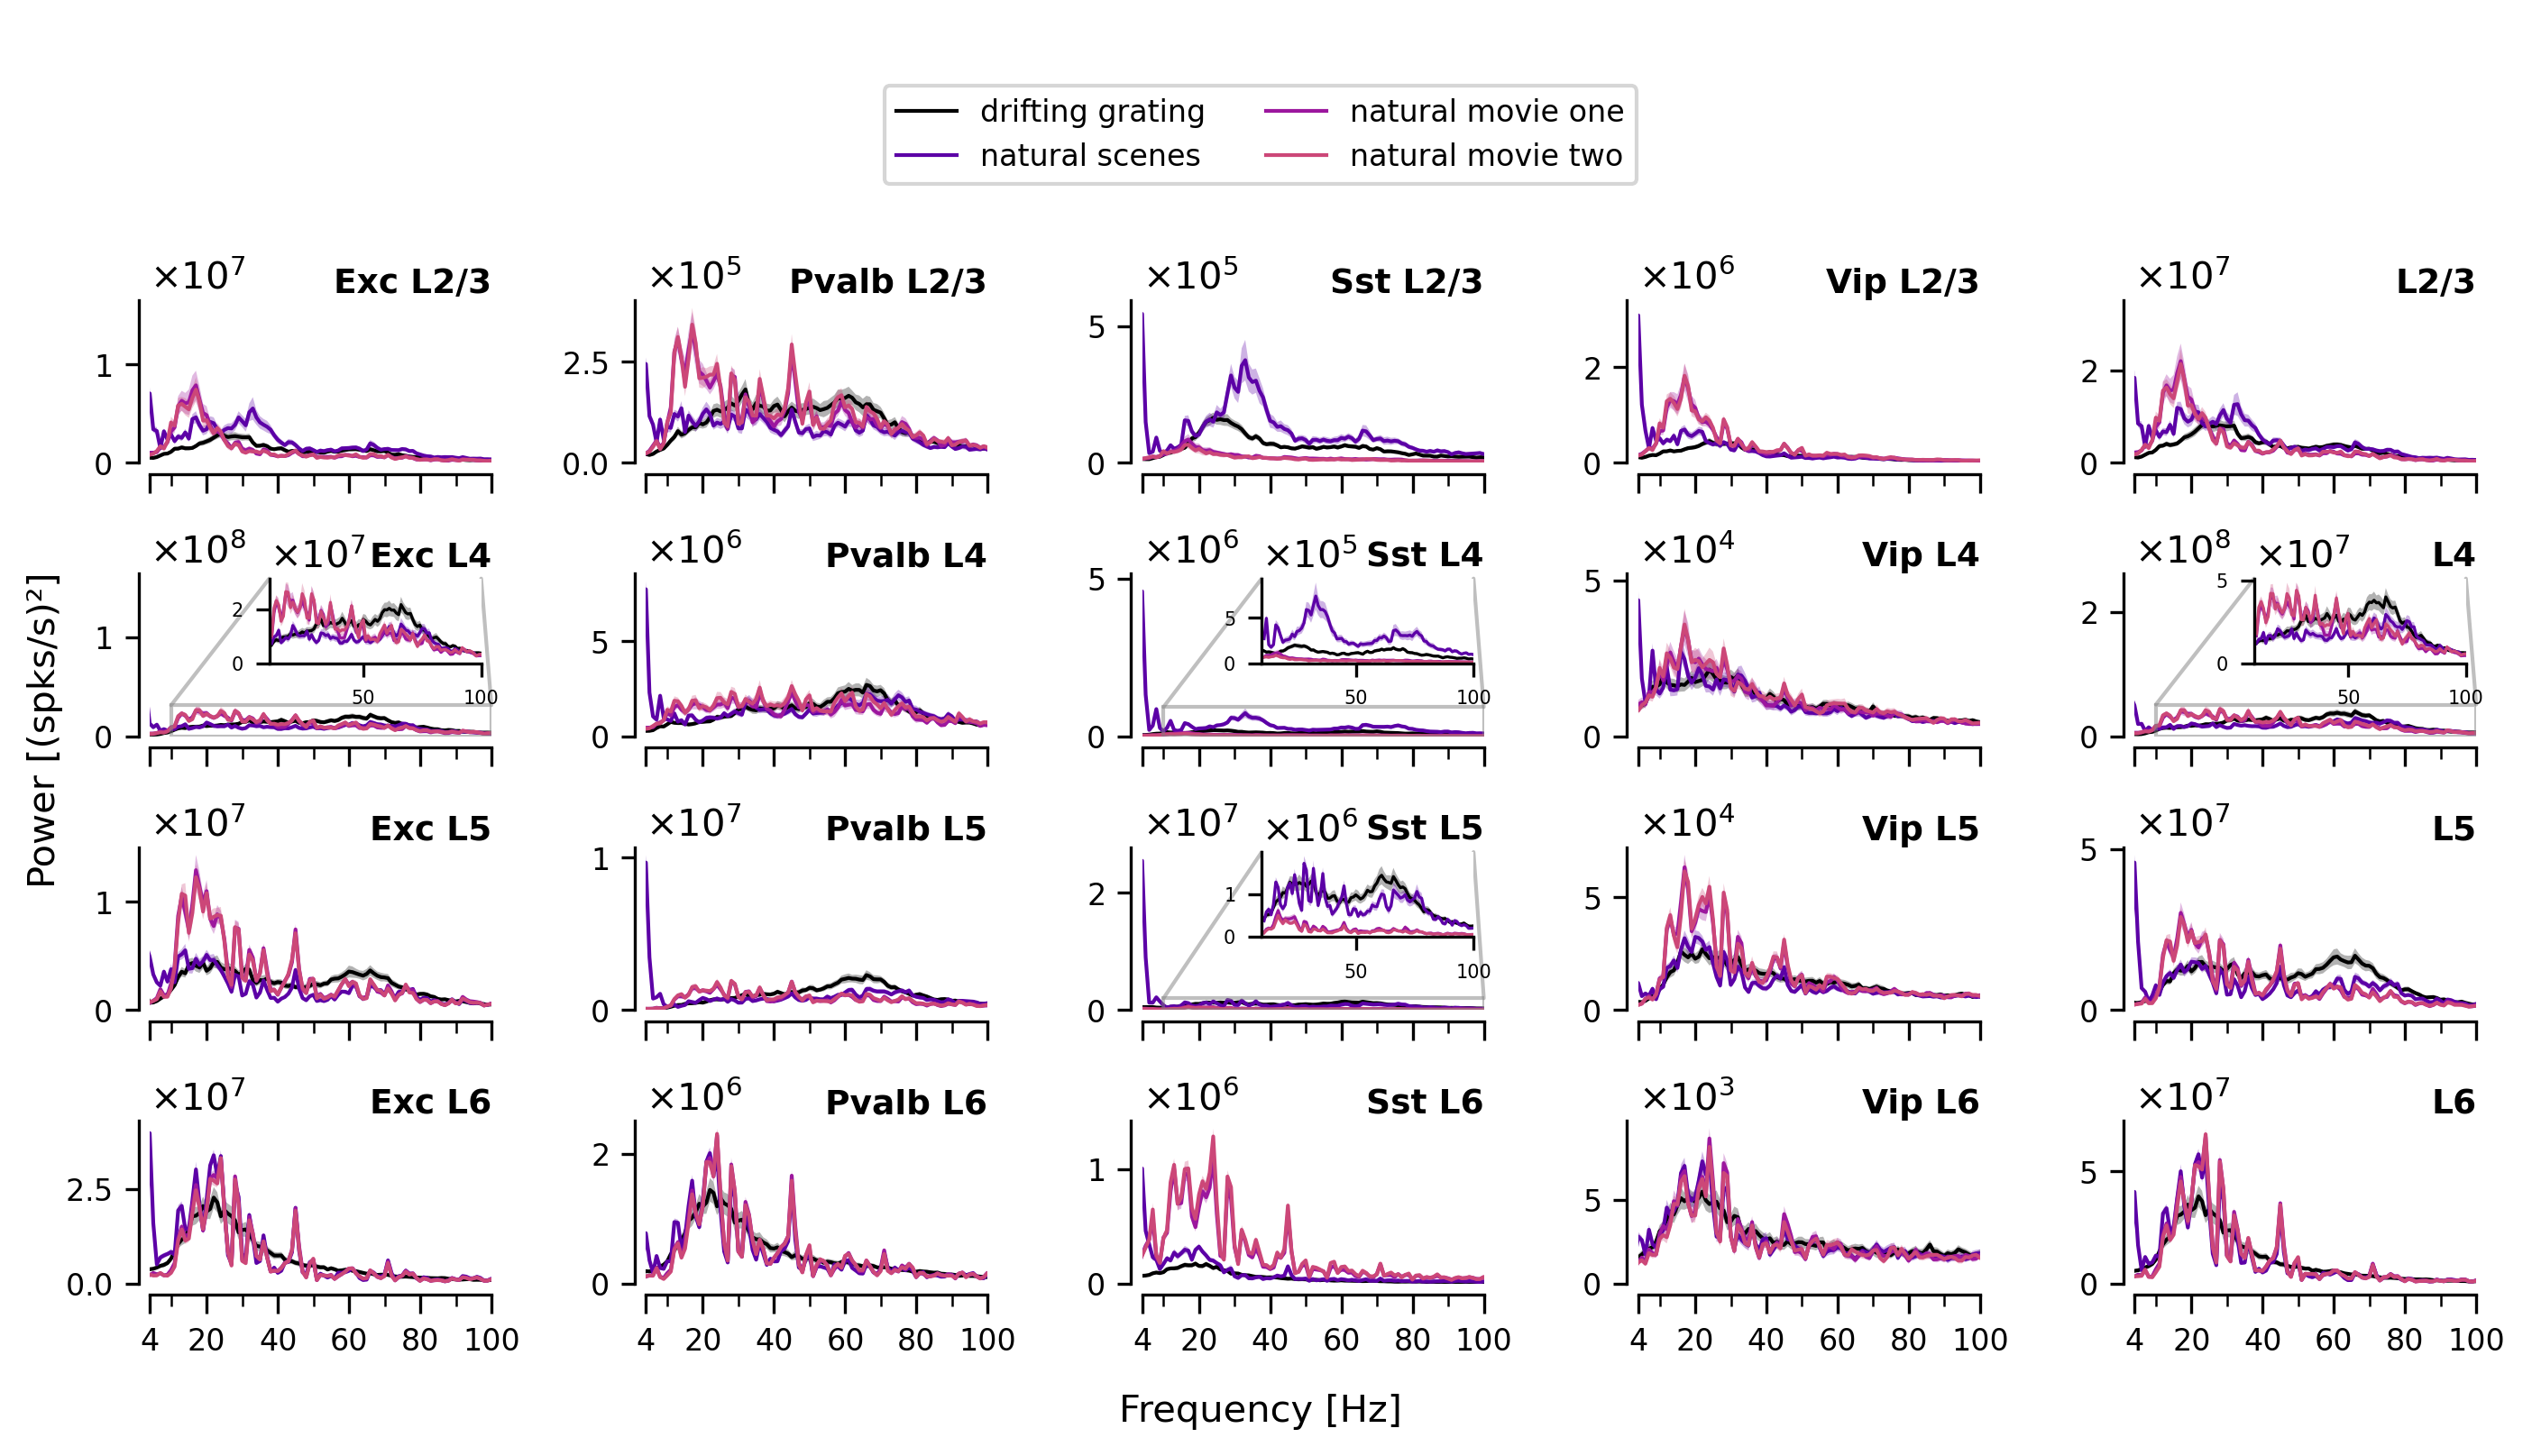

In [8]:

import matplotlib.patches as mpatches
from matplotlib.lines import Line2D

selected_cells = ["Exc", "Pvalb", "Sst", "Vip"]

stim_conditions = ['drifting grating', 'natural scenes', 'natural movie one', 'natural movie two']
plasma_colors = np.delete(plt.colormaps["plasma"](np.linspace(0, 1, 7)), 6, axis=0)
stim_palette = {
    'drifting grating':  'k',
    'natural scenes':    plasma_colors[1],
    'natural movie one': plasma_colors[2],
    'natural movie two': plasma_colors[3],
}

INSET_XLIM = [10, 100]
# (row, col) grid positions that get an inset — row 0 is the legend row
INSET_PANELS = {(2, 0), (2, 2), (3, 2), (2, 4)}

fig, axes = plt.subplots(ncols=5, nrows=5, sharex=True, figsize=(9.5, 5.5), dpi=300)
fig.patch.set_facecolor("none")
f = power_pop_name_df.loc[0, "f"]
f_arr = f[1:]  # skip DC
high_mask = f_arr >= 10

panel_data = {}  # stores (row, col) → means_ses for inset generation


def plot_panel(ax, f_arr, means_ses, label_text, sci_limits=(-3, 3)):
    """Plot all stimulus conditions on ax and style axes."""
    for cond, m, s in means_ses:
        c = stim_palette[cond]
        ax.plot(f_arr, m[1:], color=c, linewidth=1, label=cond)
        ax.fill_between(
            f_arr,
            m[1:] - 1.96 * s[1:],
            m[1:] + 1.96 * s[1:],
            facecolor=c, alpha=0.3, linewidth=0,
        )
    sns.despine(ax=ax)
    ax.spines["left"].set_position(("outward", 3))
    ax.spines["bottom"].set_position(("outward", 3))
    ax.set_xlim([4, 100])
    ax.set_xticks([4, 20, 40, 60, 80, 100])
    ax.set_xticklabels([4, 20, 40, 60, 80, 100], fontsize=8)
    ax.set_xticks([10, 30, 50, 70, 90], minor=True)
    ax.tick_params(axis='x', which='major', length=5)
    ax.tick_params(axis='x', which='minor', length=3)
    formatter = ScalarFormatter(useMathText=True)
    formatter.set_powerlimits(sci_limits)
    ax.yaxis.set_major_formatter(formatter)
    ax.ticklabel_format(axis="y", style="scientific", scilimits=sci_limits)
    ax.tick_params(axis='y', labelsize=8)
    ax.set_ylim(bottom=0)
    ax.set_title(label_text, loc="right", fontsize=9, fontweight="bold", pad=2)


def add_inset(ax, f_arr, high_mask, means_ses):
    """Add a zoom inset showing the INSET_XLIM range."""
    inset_ax = ax.inset_axes([0.35, 0.45, 0.62, 0.52])
    for cond, m, s in means_ses:
        c = stim_palette[cond]
        inset_ax.plot(f_arr[high_mask], m[1:][high_mask], color=c, linewidth=0.8)
        inset_ax.fill_between(
            f_arr[high_mask],
            m[1:][high_mask] - 1.96 * s[1:][high_mask],
            m[1:][high_mask] + 1.96 * s[1:][high_mask],
            facecolor=c, alpha=0.3, linewidth=0,
        )
    inset_ax.set_xlim(INSET_XLIM)
    inset_ax.set_ylim(bottom=0)
    inset_ax.tick_params(labelsize=5)
    formatter_ins = ScalarFormatter(useMathText=True)
    formatter_ins.set_powerlimits((-3, 3))
    inset_ax.yaxis.set_major_formatter(formatter_ins)
    inset_ax.ticklabel_format(axis="y", style="scientific", scilimits=(-3, 3))
    sns.despine(ax=inset_ax)
    ax.indicate_inset_zoom(inset_ax, edgecolor="gray")


# Columns 0–3: cell-type specific (power_pop_name_df)
for jj, cell in enumerate(selected_cells):
    for ii, layer in enumerate(layers[1:]):
        row = ii + 1  # row 0 is reserved for legend
        ax = axes[row, jj]
        means_ses = []
        for cond in stim_conditions:
            subset = power_pop_name_df.query(
                f'condition == "{cond}" & cell == "{cell}" & layer == "{layer}"'
            )
            if len(subset) == 0:
                continue
            means_ses.append((cond, subset["mean"].values[0], subset["se"].values[0]))
        plot_panel(ax, f_arr, means_ses, cell + " " + layer)
        panel_data[(row, jj)] = means_ses

# Column 4: all-populations combined (power_layers_df)
for ii, layer in enumerate(layers[1:]):
    row = ii + 1
    ax = axes[row, 4]
    means_ses = []
    for cond in stim_conditions:
        subset = power_layers_df.query(f'condition == "{cond}" & layer == "{layer}"')
        if len(subset) == 0:
            continue
        means_ses.append((cond, subset["mean"].values[0], subset["se"].values[0]))
    plot_panel(ax, f_arr, means_ses, layer, sci_limits=(-3, 2))
    panel_data[(row, 4)] = means_ses

# Add insets only to specified panels
for (row, col) in INSET_PANELS:
    if (row, col) in panel_data:
        add_inset(axes[row, col], f_arr, high_mask, panel_data[(row, col)])

# Row 0: legend row — hide all axes, place legend in centre of top row
for jj in range(5):
    axes[0, jj].set_axis_off()

legend_elements = [
    Line2D([0], [0], color=stim_palette[cond], linewidth=1, label=cond)
    for cond in stim_conditions
]
fig.legend(
    handles=legend_elements,
    loc="center",
    bbox_to_anchor=(0.5, 0.9),
    mode=None,
    borderaxespad=0.0,
    fontsize=8,
    ncols=2,
)
fig.supxlabel("Frequency [Hz]", fontsize=10, y=0.03)
fig.supylabel("Power [(spks/s)²]", fontsize=10)
fig.tight_layout()
fig.savefig(
    "paper_figs/fig2C_dg_power_Jul27_2026.pdf",
    dpi=300,
    bbox_inches="tight",
    transparent=True,
)


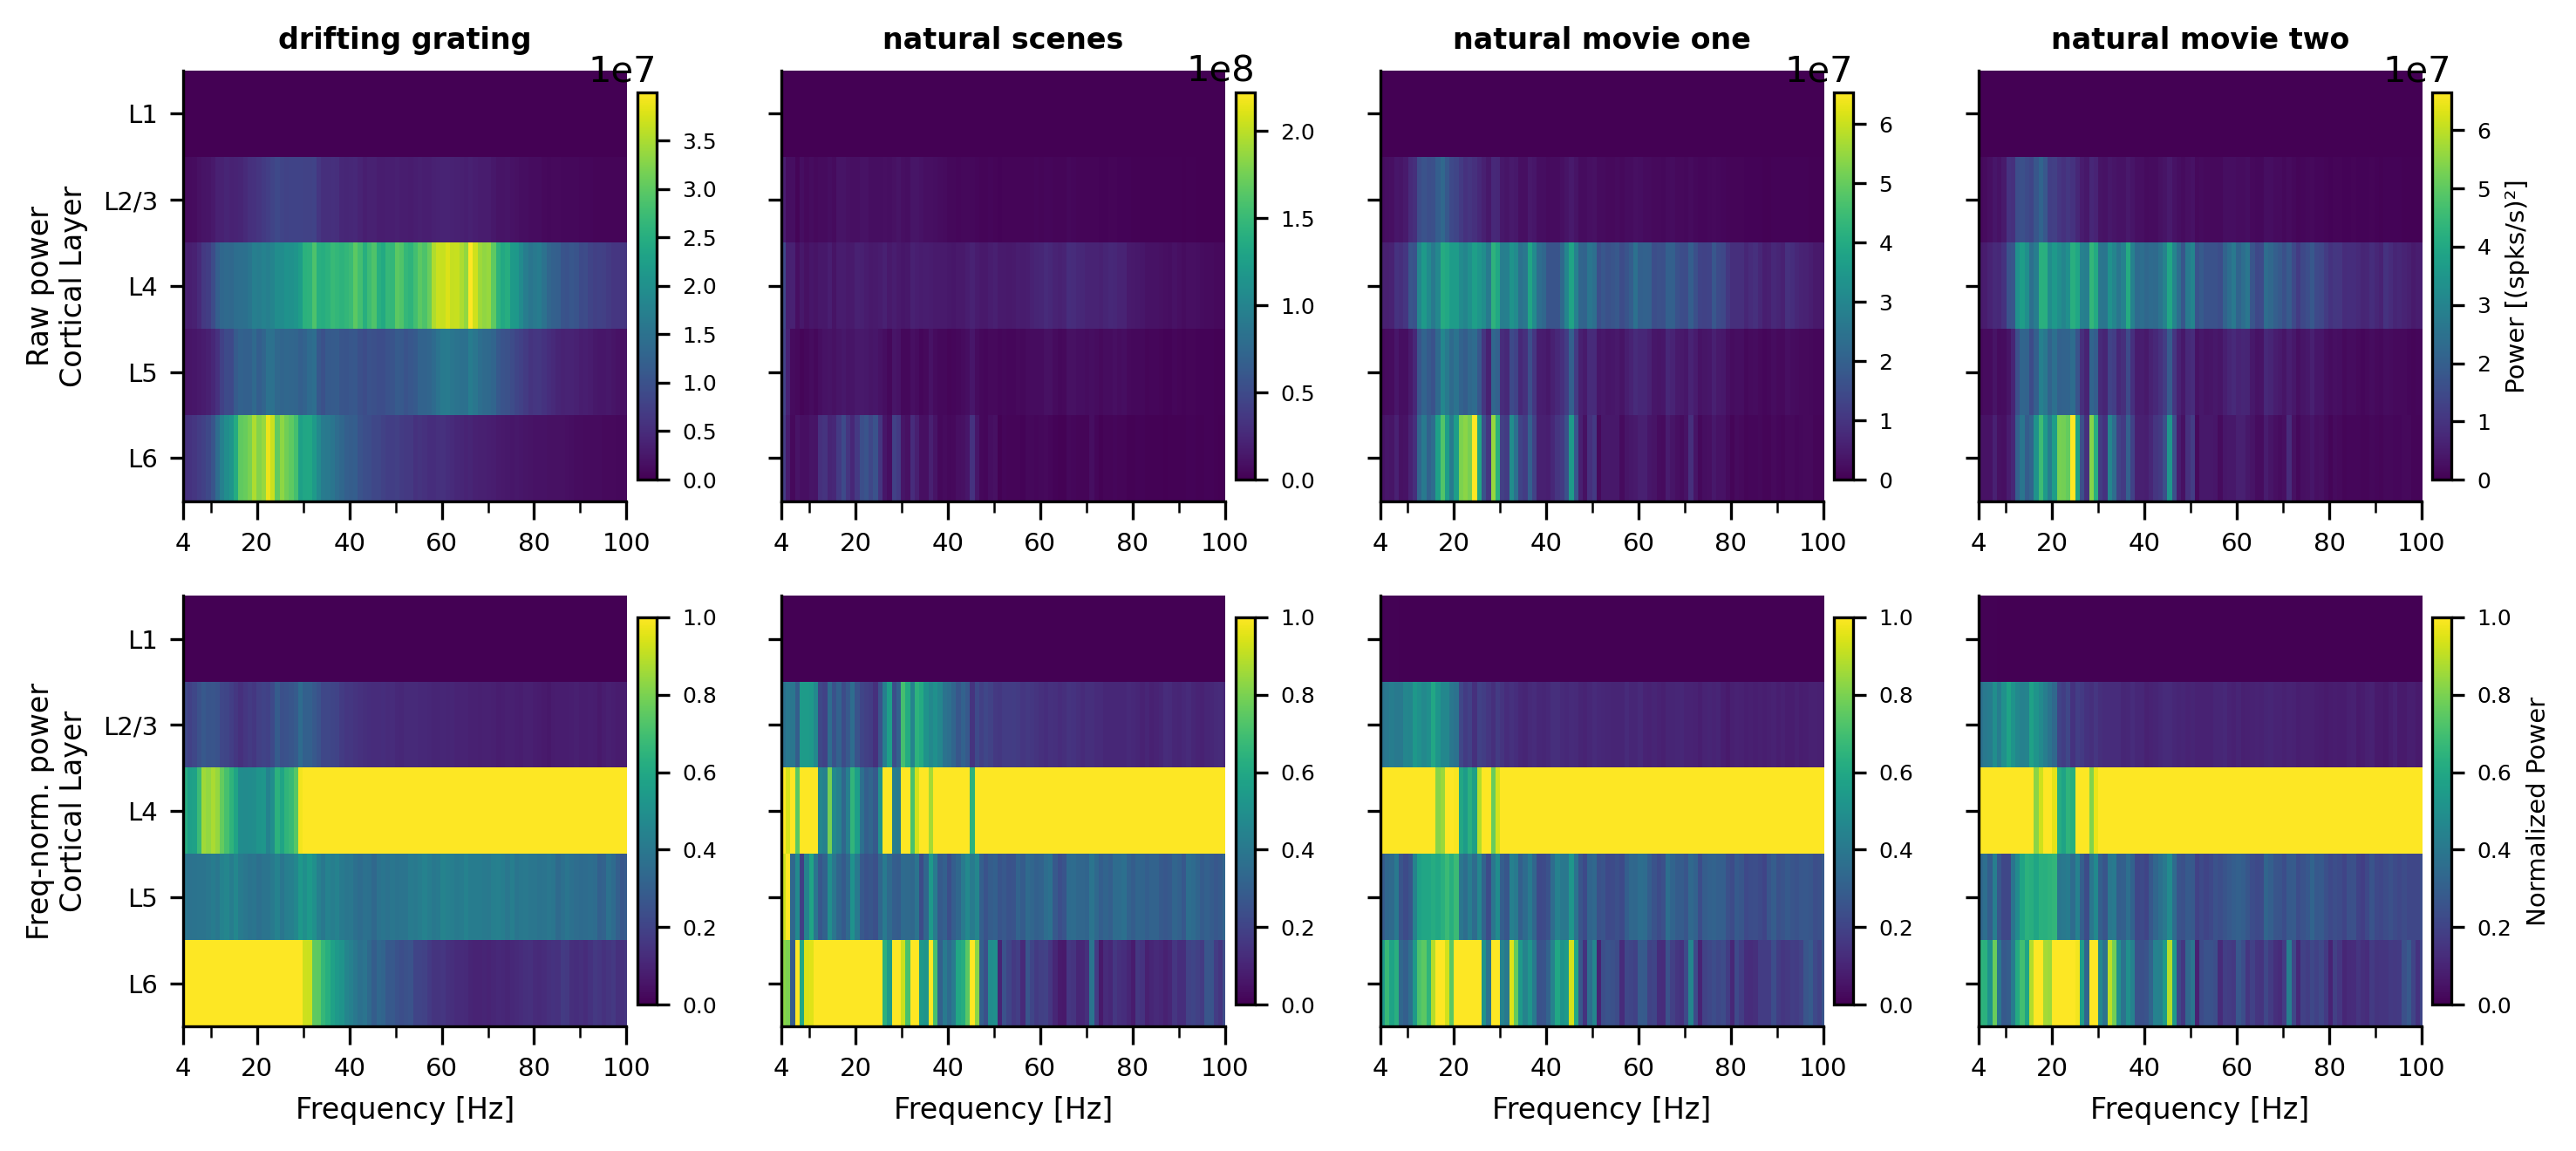

In [9]:

stim_conditions = ['drifting grating', 'natural scenes', 'natural movie one', 'natural movie two']
layers_all = layers  # L1–L6

f_ref = power_layers_df.loc[0, "f"]

# Build raw and frequency-normalized power matrices per condition
power_matrices = {}
power_matrices_norm = {}
for cond in stim_conditions:
    data = power_layers_df.query(f'condition == "{cond}"')
    pm = np.zeros((len(layers_all), len(f_ref[1:])))
    for i, layer in enumerate(layers_all):
        row = data[data["layer"] == layer]
        if len(row) > 0:
            pm[i, :] = row["mean"].iloc[0][1:]
    power_matrices[cond] = pm
    max_per_freq = np.max(pm, axis=0)
    max_per_freq[max_per_freq == 0] = 1
    power_matrices_norm[cond] = pm / max_per_freq

fig, axes = plt.subplots(ncols=4, nrows=2, figsize=(10, 4.5), dpi=300)
fig.patch.set_facecolor("none")

for jj, cond in enumerate(stim_conditions):
    # ── Row 0: raw power (per-panel colorscale) ──
    ax0 = axes[0, jj]
    pm = power_matrices[cond]
    im0 = ax0.imshow(
        pm,
        aspect="auto",
        origin="upper",
        extent=[f_ref[1], f_ref[-1], len(layers_all), 0],
        cmap="viridis",
        vmin=0,
        vmax=np.max(pm),
    )
    ax0.set_xlim([4, 100])
    ax0.set_xticks([4, 20, 40, 60, 80, 100])
    ax0.set_xticklabels([4, 20, 40, 60, 80, 100], fontsize=7)
    ax0.set_xticks([10, 30, 50, 70, 90], minor=True)
    ax0.tick_params(axis='x', which='major', length=5, labelsize=7)
    ax0.tick_params(axis='x', which='minor', length=3)
    ax0.set_title(cond, fontsize=8, fontweight="bold")
    ax0.set_yticks(np.arange(len(layers_all)) + 0.5)
    ax0.spines["top"].set_visible(False)
    ax0.spines["right"].set_visible(False)
    if jj == 0:
        ax0.set_yticklabels(layers_all, fontsize=7)
        ax0.set_ylabel("Raw power\nCortical Layer", fontsize=8)
    else:
        ax0.set_yticklabels([])
    cbar0 = fig.colorbar(im0, ax=ax0, shrink=0.9, pad=0.02)
    cbar0.ax.tick_params(labelsize=6)
    cbar0.ax.yaxis.set_offset_position("right")  # keep 1e* clear of the image
    if jj == 3:
        cbar0.set_label("Power [(spks/s)²]", fontsize=7)

    # ── Row 1: freq-normalized power (per-panel colorscale) ──
    ax1 = axes[1, jj]
    pm_norm = power_matrices_norm[cond]
    im1 = ax1.imshow(
        pm_norm,
        aspect="auto",
        origin="upper",
        extent=[f_ref[1], f_ref[-1], len(layers_all), 0],
        cmap="viridis",
        vmin=0,
        vmax=1,
    )
    ax1.set_xlim([4, 100])
    ax1.set_xticks([4, 20, 40, 60, 80, 100])
    ax1.set_xticklabels([4, 20, 40, 60, 80, 100], fontsize=7)
    ax1.set_xticks([10, 30, 50, 70, 90], minor=True)
    ax1.tick_params(axis='x', which='major', length=5, labelsize=7)
    ax1.tick_params(axis='x', which='minor', length=3)
    ax1.tick_params(axis='y', which='major', labelsize=7)
    ax1.set_xlabel("Frequency [Hz]", fontsize=8)
    ax1.set_yticks(np.arange(len(layers_all)) + 0.5)
    ax1.spines["top"].set_visible(False)
    ax1.spines["right"].set_visible(False)
    if jj == 0:
        ax1.set_yticklabels(layers_all, fontsize=7)
        ax1.set_ylabel("Freq-norm. power\nCortical Layer", fontsize=8)
    else:
        ax1.set_yticklabels([])
    cbar1 = fig.colorbar(im1, ax=ax1, shrink=0.9, pad=0.02)
    cbar1.ax.tick_params(labelsize=6)
    cbar1.ax.yaxis.set_offset_position("right")
    if jj == 3:
        cbar1.set_label("Normalized Power", fontsize=7)

fig.tight_layout()
fig.savefig(
    "paper_figs/fig2C_laminar_power_colormap_all_stim_Jun16_2026.pdf",
    dpi=300,
    bbox_inches="tight",
    transparent=True,
)


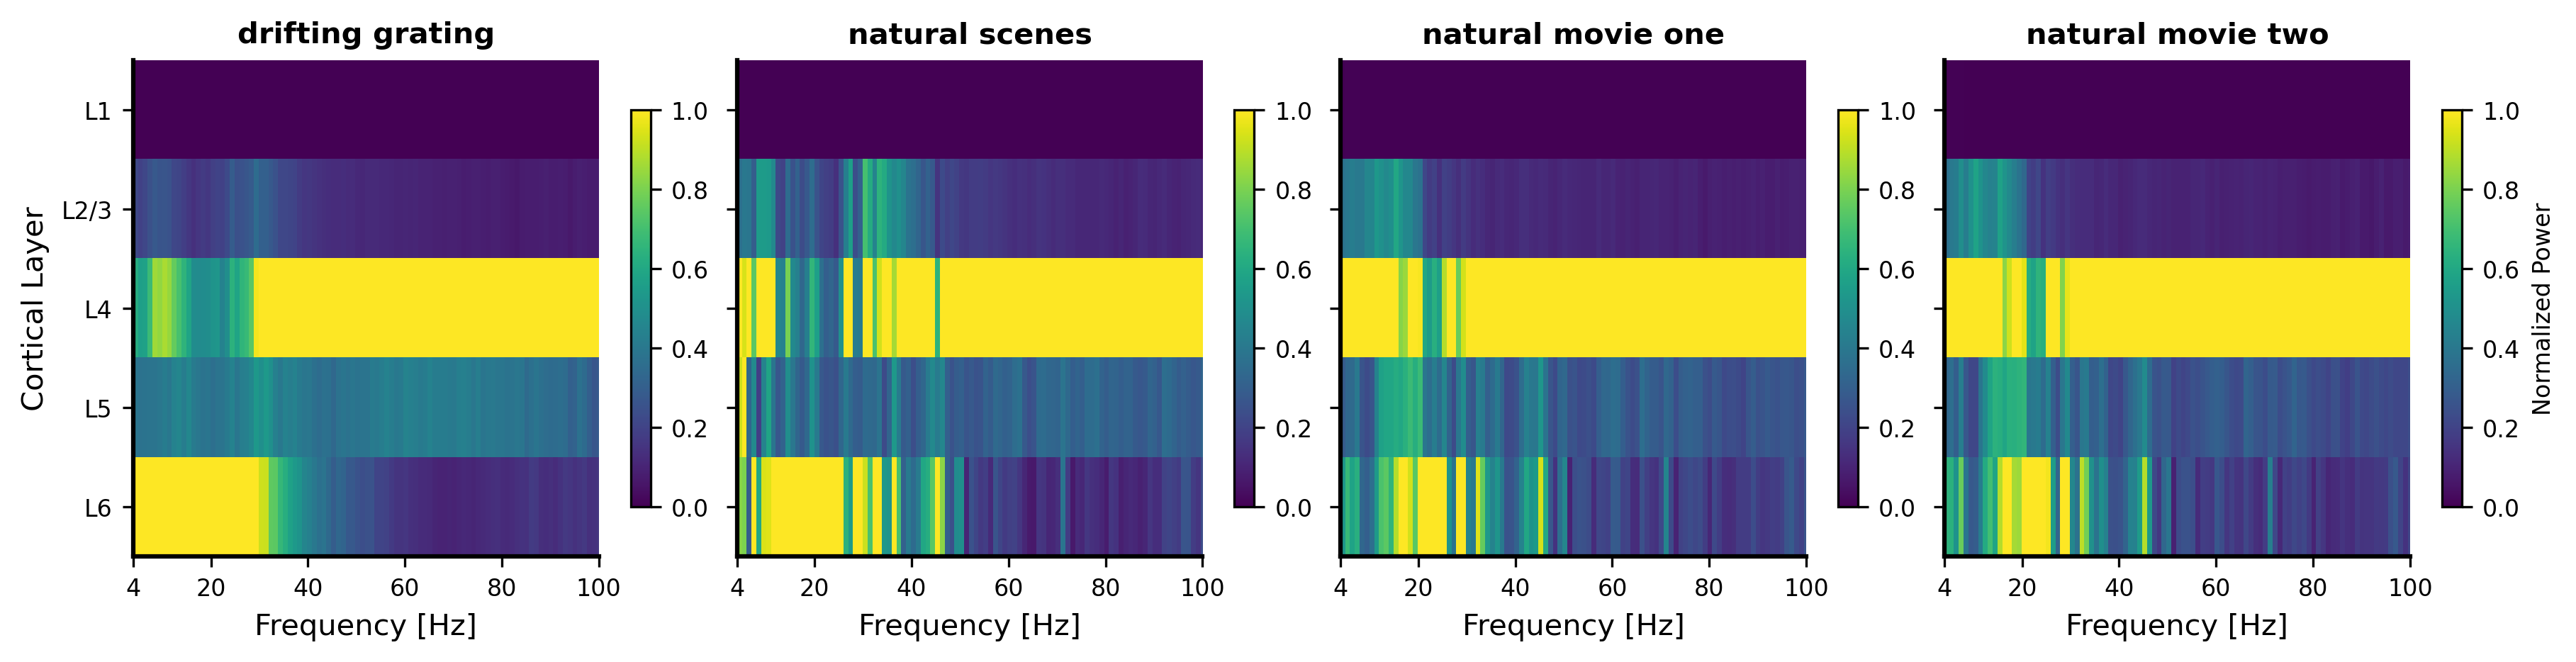

In [10]:
# ── Publication-ready: freq-normalized power maps, 4 conditions ──────────────
# Style matches fig1C laminar colormap (cell 13):
#   fontsize 10 labels/titles, 8 ticks, xticks [4,20,40,60,80,100],
#   spines top/right off, left/bottom lw=1.5, colorbar shrink=0.8

stim_conditions = ['drifting grating', 'natural scenes', 'natural movie one', 'natural movie two']
extent_pub = [f_ref[1], f_ref[-1], len(layers_all), 0]
xticks_pub = [4, 20, 40, 60, 80, 100]

fig_pub, axes_pub = plt.subplots(nrows=1, ncols=4, figsize=(12, 3), dpi=300,
                                  constrained_layout=True)
fig_pub.patch.set_facecolor("none")

for jj, cond in enumerate(stim_conditions):
    ax = axes_pub[jj]
    im = ax.imshow(
        power_matrices_norm[cond],
        aspect="auto",
        origin="upper",
        extent=extent_pub,
        cmap="viridis",
        vmin=0,
        vmax=1,
    )
    ax.set_xlim([4, 100])
    ax.set_xticks(xticks_pub)
    ax.set_xticklabels(xticks_pub, fontsize=8)
    ax.set_xlabel("Frequency [Hz]", fontsize=10)
    ax.set_yticks(np.arange(len(layers_all)) + 0.5)
    if jj == 0:
        ax.set_yticklabels(layers_all, fontsize=8)
        ax.set_ylabel("Cortical Layer", fontsize=10)
    else:
        ax.set_yticklabels([])
    ax.set_title(cond, fontsize=10, fontweight="bold", pad=6)
    ax.tick_params(axis="both", which="major", labelsize=8)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_linewidth(1.5)
    ax.spines["bottom"].set_linewidth(1.5)

    cbar = fig_pub.colorbar(im, ax=ax, shrink=0.8, pad=0.02)
    cbar.ax.tick_params(labelsize=8)
    cbar.ax.yaxis.set_offset_position("right")
    if jj == 3:
        cbar.set_label("Normalized Power", fontsize=8)

fig_pub.savefig(
    "paper_figs/fig2C_laminar_norm_power_pub_May28.pdf",
    dpi=300,
    bbox_inches="tight",
    transparent=True,
)


Pearson correlation with drifting grating

Condition                     raw r       raw p    norm r      norm p
----------------------------------------------------------------------
natural scenes               0.5591  1.032e-103    0.9624   0.000e+00
natural movie one            0.8395   0.000e+00    0.9561   0.000e+00
natural movie two            0.8507   0.000e+00    0.9529   0.000e+00

Per-layer Pearson r (raw power)

Layer     natural scenes  natural movie   natural movie 
--------------------------------------------------------------
L1                0.6736          0.6998          0.6954
L2/3              0.7122          0.6834          0.6908
L4                0.3600          0.7992          0.8183
L5                0.6239          0.7399          0.7399
L6                0.8795          0.9001          0.8965


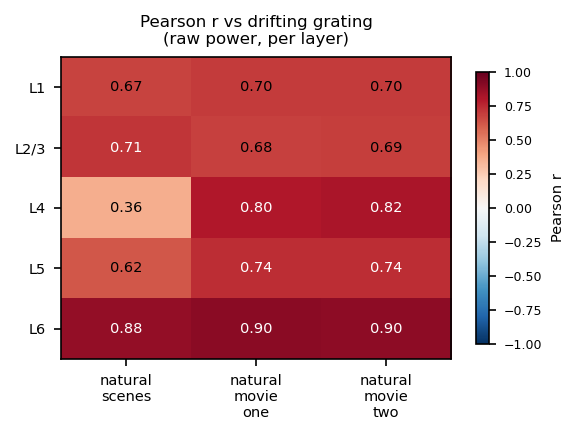

In [11]:
from scipy.stats import pearsonr

ref_cond = 'drifting grating'
compare_conds = ['natural scenes', 'natural movie one', 'natural movie two']

# ── Overall Pearson r (all layers × frequencies flattened) ──────────────────
print("Pearson correlation with drifting grating\n")
print(f"{'Condition':<25}  {'raw r':>8}  {'raw p':>10}  {'norm r':>8}  {'norm p':>10}")
print("-" * 70)
for cond in compare_conds:
    r_raw, p_raw   = pearsonr(power_matrices[ref_cond].flatten(),
                               power_matrices[cond].flatten())
    r_norm, p_norm = pearsonr(power_matrices_norm[ref_cond].flatten(),
                               power_matrices_norm[cond].flatten())
    print(f"{cond:<25}  {r_raw:>8.4f}  {p_raw:>10.3e}  {r_norm:>8.4f}  {p_norm:>10.3e}")

# ── Per-layer Pearson r ──────────────────────────────────────────────────────
print("\nPer-layer Pearson r (raw power)\n")
header = f"{'Layer':<8}" + "".join(f"  {c[:14]:>14}" for c in compare_conds)
print(header)
print("-" * (8 + 18 * len(compare_conds)))
for i, layer in enumerate(layers_all):
    row_str = f"{layer:<8}"
    for cond in compare_conds:
        r_l, _ = pearsonr(power_matrices[ref_cond][i, :], power_matrices[cond][i, :])
        row_str += f"  {r_l:>14.4f}"
    print(row_str)

# ── Heatmap of per-layer r values ────────────────────────────────────────────
r_matrix = np.zeros((len(layers_all), len(compare_conds)))
for i, layer in enumerate(layers_all):
    for j, cond in enumerate(compare_conds):
        r_matrix[i, j], _ = pearsonr(
            power_matrices[ref_cond][i, :], power_matrices[cond][i, :]
        )

fig_sim, ax_sim = plt.subplots(figsize=(4, 3), dpi=150)
im_sim = ax_sim.imshow(r_matrix, cmap="RdBu_r", vmin=-1, vmax=1, aspect="auto")
ax_sim.set_xticks(range(len(compare_conds)))
ax_sim.set_xticklabels([c.replace(" ", "\n") for c in compare_conds], fontsize=7)
ax_sim.set_yticks(range(len(layers_all)))
ax_sim.set_yticklabels(layers_all, fontsize=7)
ax_sim.set_title("Pearson r vs drifting grating\n(raw power, per layer)", fontsize=8)
for i in range(len(layers_all)):
    for j in range(len(compare_conds)):
        ax_sim.text(j, i, f"{r_matrix[i, j]:.2f}", ha="center", va="center",
                    fontsize=7, color="k" if abs(r_matrix[i, j]) < 0.7 else "w")
cbar_sim = fig_sim.colorbar(im_sim, ax=ax_sim, shrink=0.9)
cbar_sim.set_label("Pearson r", fontsize=7)
cbar_sim.ax.tick_params(labelsize=6)
fig_sim.tight_layout()
fig_sim.savefig(
    "paper_figs/fig2C_power_similarity_vs_dg_Jun16_2026.pdf",
    dpi=300,
    bbox_inches="tight",
    transparent=True,
)


Image similarity vs drifting grating (freq-normalized maps)

Condition                      SSIM   Pearson r         MSE
----------------------------------------------------------
natural scenes               0.9513      0.9624    0.009636
natural movie one            0.9485      0.9561    0.011238
natural movie two            0.9454      0.9529    0.012034


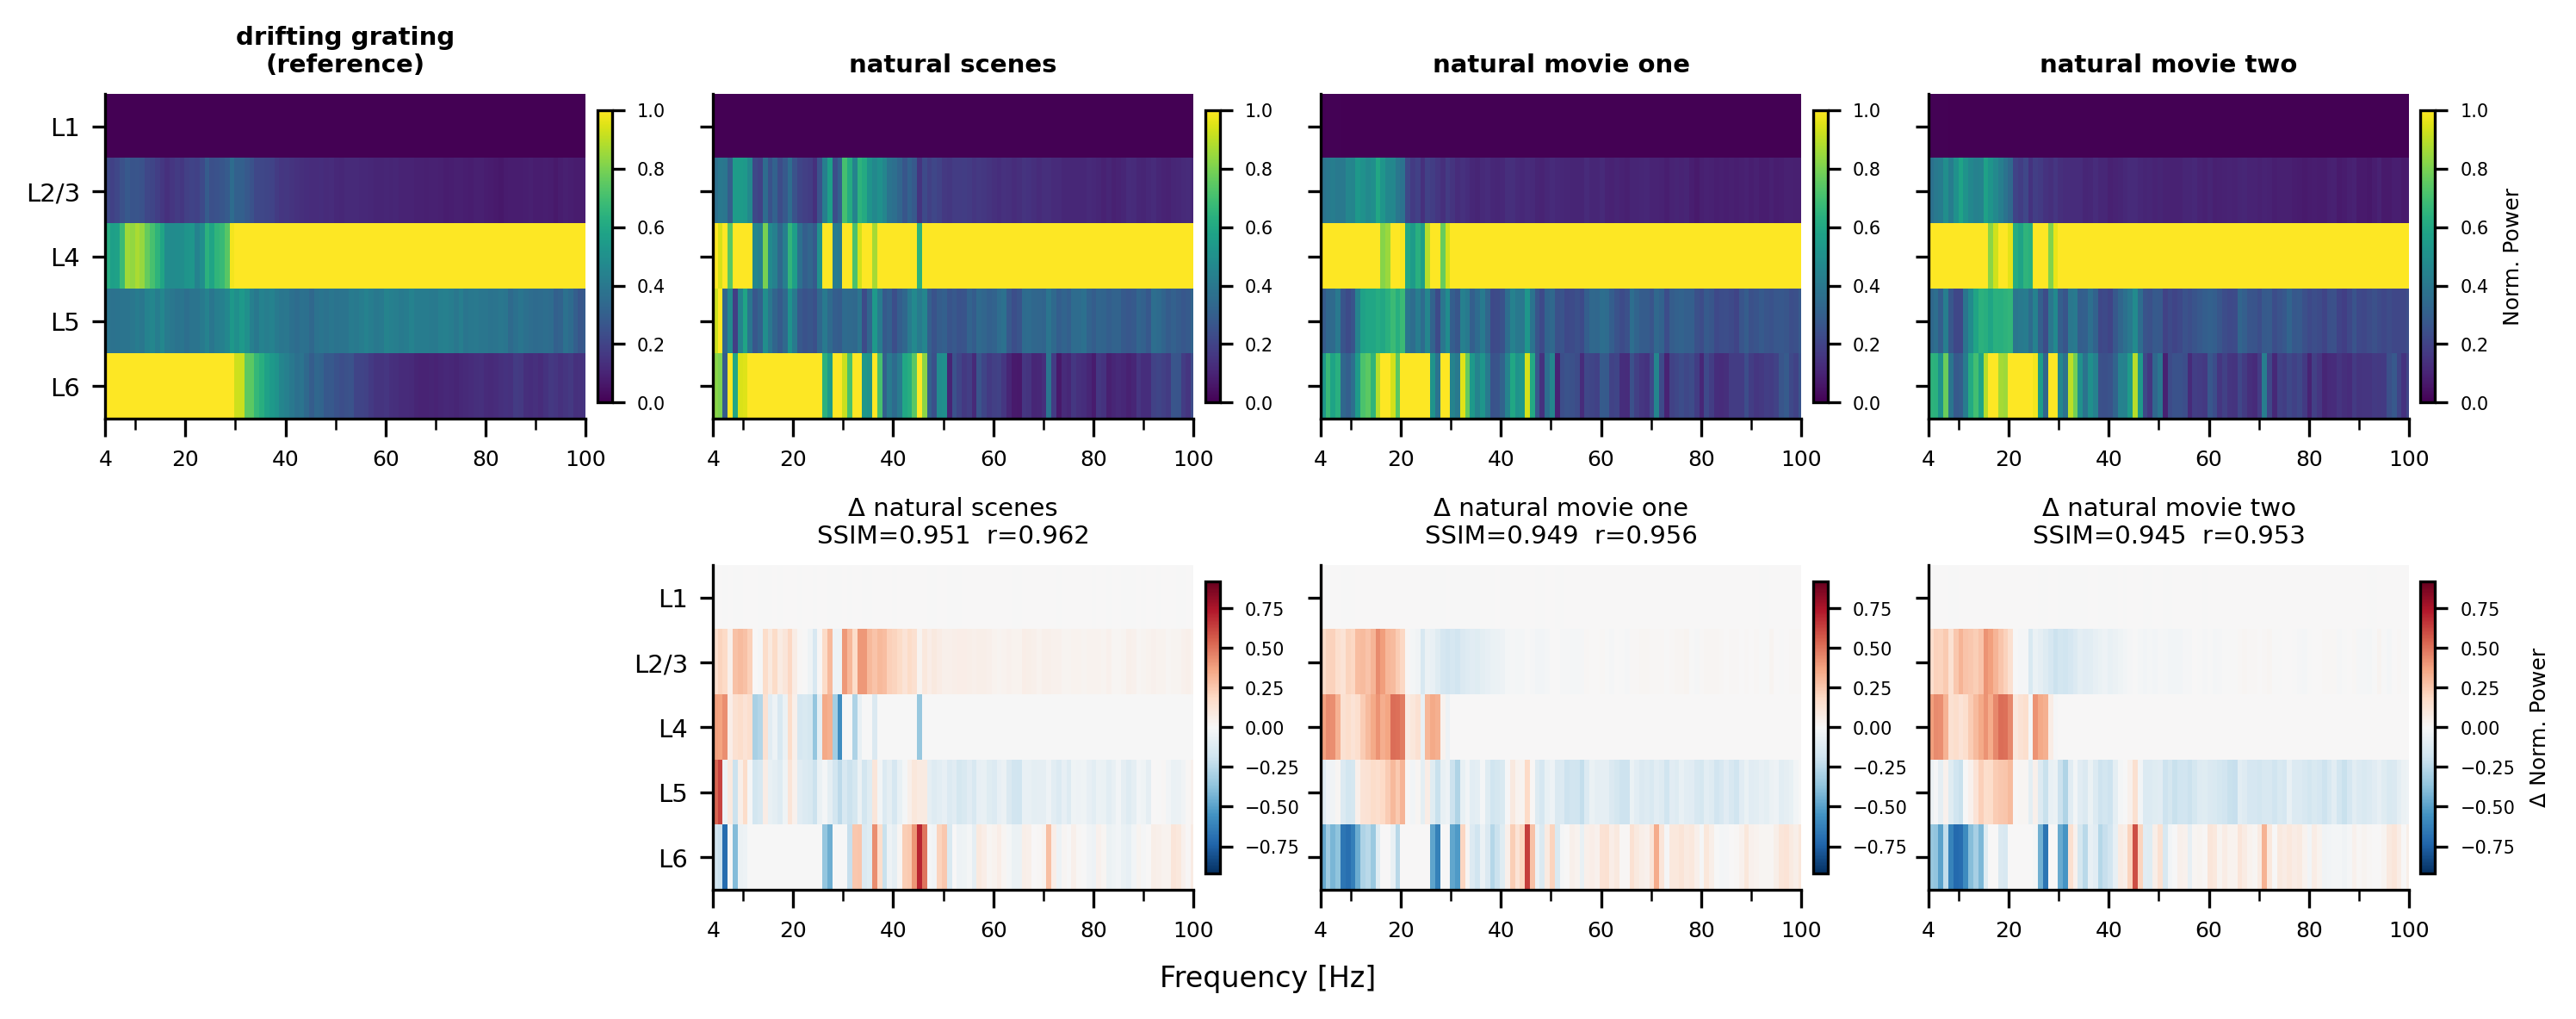

In [12]:

from skimage.metrics import structural_similarity as ssim

ref_cond = 'drifting grating'
compare_conds = ['natural scenes', 'natural movie one', 'natural movie two']

ref_img = power_matrices_norm[ref_cond]
f_ref_vals = f_ref[1:]
extent = [f_ref_vals[0], f_ref_vals[-1], len(layers_all), 0]

# ── Image similarity metrics ─────────────────────────────────────────────────
print("Image similarity vs drifting grating (freq-normalized maps)\n")
print(f"{'Condition':<25}  {'SSIM':>8}  {'Pearson r':>10}  {'MSE':>10}")
print("-" * 58)
img_metrics = {}
for cond in compare_conds:
    img = power_matrices_norm[cond]
    s   = ssim(ref_img, img, data_range=1.0, win_size=3)
    r, _ = pearsonr(ref_img.flatten(), img.flatten())
    mse = np.mean((ref_img - img) ** 2)
    img_metrics[cond] = dict(ssim=s, pearsonr=r, mse=mse)
    print(f"{cond:<25}  {s:>8.4f}  {r:>10.4f}  {mse:>10.6f}")

# ── Figure: normalized maps (row 0) + difference maps (row 1) ───────────────
fig, axes = plt.subplots(nrows=2, ncols=4, figsize=(12, 4), dpi=300,
                         gridspec_kw={"hspace": 0.45, "wspace": 0.05})
fig.patch.set_facecolor("none")

# Row 0 — normalized maps for all 4 conditions
for jj, cond in enumerate([ref_cond] + compare_conds):
    ax = axes[0, jj]
    img = power_matrices_norm[cond]
    im = ax.imshow(img, aspect="auto", origin="upper", extent=extent,
                   cmap="viridis", vmin=0, vmax=1)
    ax.set_xlim([4, 100])
    ax.set_xticks([4, 20, 40, 60, 80, 100])
    ax.set_xticklabels([4, 20, 40, 60, 80, 100], fontsize=6)
    ax.set_xticks([10, 30, 50, 70, 90], minor=True)
    ax.tick_params(axis='x', which='major', length=5)
    ax.tick_params(axis='x', which='minor', length=3)
    ax.set_yticks(np.arange(len(layers_all)) + 0.5)
    ax.set_yticklabels(layers_all if jj == 0 else [], fontsize=7)
    title = f"{cond}\n(reference)" if jj == 0 else cond
    ax.set_title(title, fontsize=7, fontweight="bold")
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    cbar = fig.colorbar(im, ax=ax, shrink=0.9, pad=0.02)
    cbar.ax.tick_params(labelsize=5)
    cbar.ax.yaxis.set_offset_position("right")
    if jj == 3:
        cbar.set_label("Norm. Power", fontsize=6)

# Row 1 — difference maps (cond − ref); col 0 left blank
axes[1, 0].axis("off")
diff_max = max(np.abs(power_matrices_norm[c] - ref_img).max() for c in compare_conds)
for jj, cond in enumerate(compare_conds):
    ax = axes[1, jj + 1]
    diff = power_matrices_norm[cond] - ref_img
    im = ax.imshow(diff, aspect="auto", origin="upper", extent=extent,
                   cmap="RdBu_r", vmin=-diff_max, vmax=diff_max)
    ax.set_xlim([4, 100])
    ax.set_xticks([4, 20, 40, 60, 80, 100])
    ax.set_xticklabels([4, 20, 40, 60, 80, 100], fontsize=6)
    ax.set_xticks([10, 30, 50, 70, 90], minor=True)
    ax.tick_params(axis='x', which='major', length=5)
    ax.tick_params(axis='x', which='minor', length=3)
    ax.set_yticks(np.arange(len(layers_all)) + 0.5)
    ax.set_yticklabels(layers_all if jj == 0 else [], fontsize=7)
    s_val = img_metrics[cond]["ssim"]
    r_val = img_metrics[cond]["pearsonr"]
    ax.set_title(f"Δ {cond}\nSSIM={s_val:.3f}  r={r_val:.3f}", fontsize=7)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    cbar = fig.colorbar(im, ax=ax, shrink=0.9, pad=0.02)
    cbar.ax.tick_params(labelsize=5)
    cbar.ax.yaxis.set_offset_position("right")
    if jj == 2:
        cbar.set_label("Δ Norm. Power", fontsize=6)

fig.supxlabel("Frequency [Hz]", fontsize=8, y=0.01)
fig.savefig(
    "paper_figs/fig2C_power_image_similarity_Jun16_2026.pdf",
    dpi=300, bbox_inches="tight", transparent=True,
)


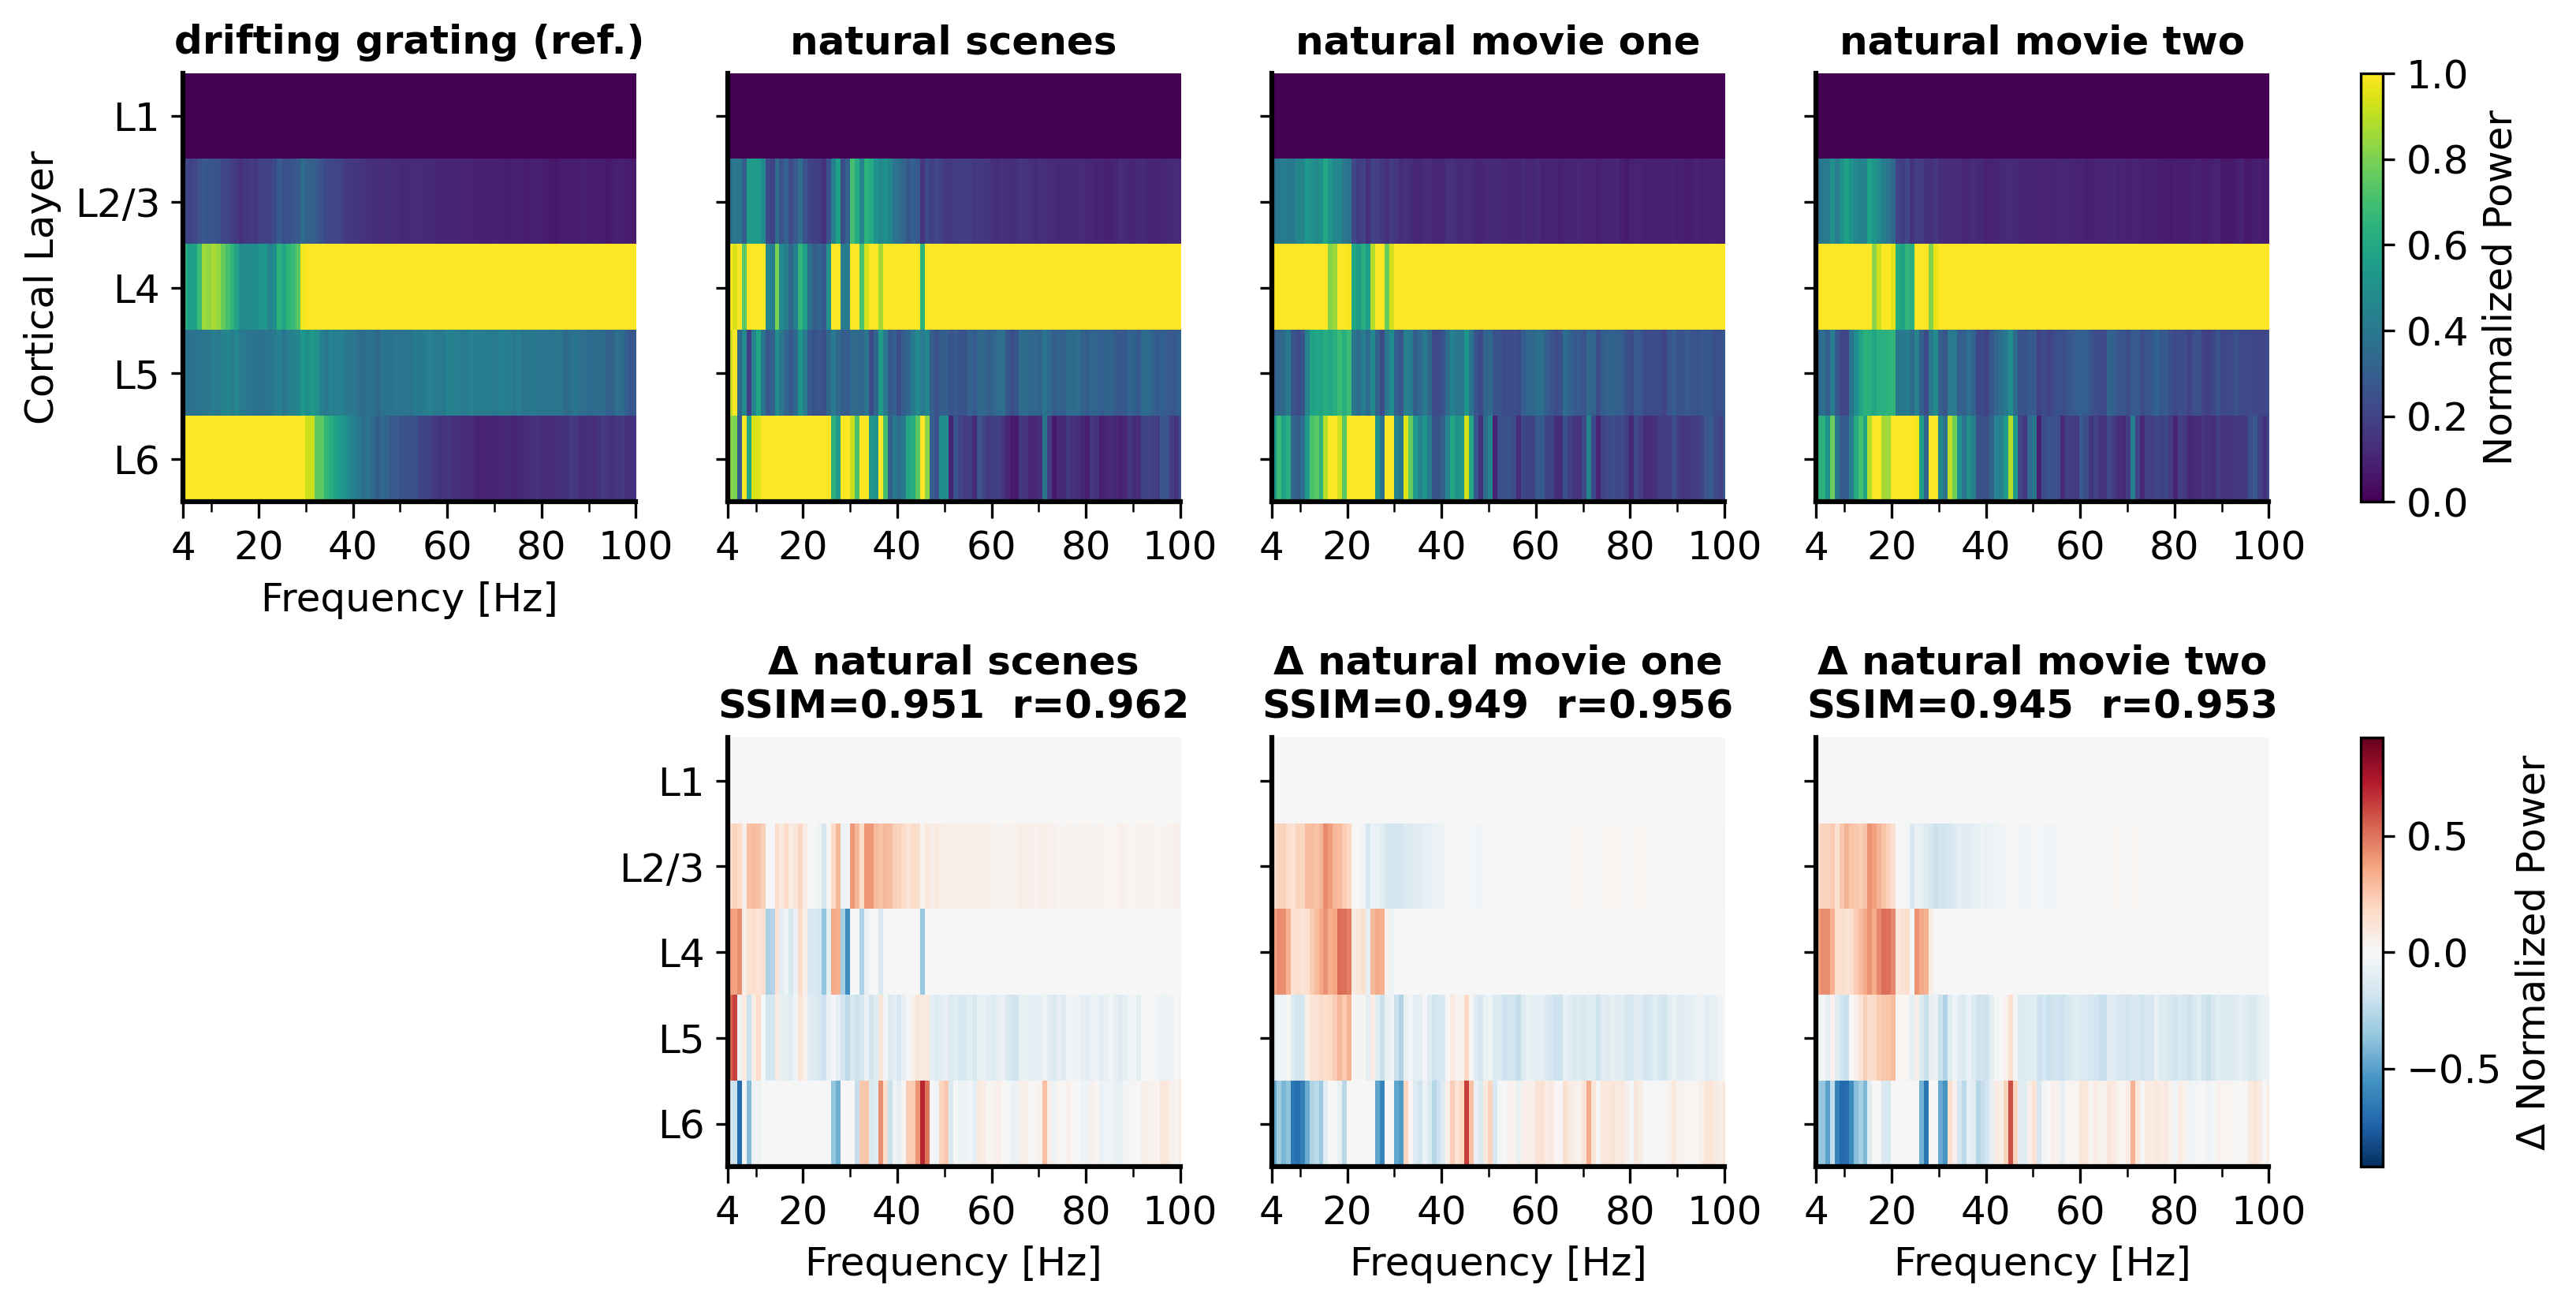

In [13]:

# ── Publication-ready: normalized maps + difference maps ──────────────────────
# Colorbar only at last column; all image axes identical size via GridSpec.
import matplotlib.gridspec as gridspec

xticks_pub   = [4, 20, 40, 60, 80, 100]
extent_pub   = [f_ref[1], f_ref[-1], len(layers_all), 0]
ref_cond_pub = 'drifting grating'
cmp_conds    = ['natural scenes', 'natural movie one', 'natural movie two']
ref_img_pub  = power_matrices_norm[ref_cond_pub]
diff_max_pub = max(np.abs(power_matrices_norm[c] - ref_img_pub).max() for c in cmp_conds)

fig_sim2 = plt.figure(figsize=(12, 6), dpi=300)
fig_sim2.patch.set_facecolor("none")

# 5 columns: 4 equal image columns + 1 narrow colorbar column
gs = gridspec.GridSpec(2, 5, figure=fig_sim2,
                       width_ratios=[1, 1, 1, 1, 0.05],
                       hspace=0.55, wspace=0.25)

axes_sim2 = np.array([[fig_sim2.add_subplot(gs[r, c]) for c in range(4)] for r in range(2)])
cbar_ax_r0 = fig_sim2.add_subplot(gs[0, 4])
cbar_ax_r1 = fig_sim2.add_subplot(gs[1, 4])


def _pub_style2(ax, show_ylabels=True, ylabel=None):
    ax.set_xlim([4, 100])
    ax.set_xticks(xticks_pub)
    ax.set_xticklabels(xticks_pub, fontsize=12)
    ax.set_xticks([10, 30, 50, 70, 90], minor=True)
    ax.tick_params(axis='x', which='major', length=5)
    ax.tick_params(axis='x', which='minor', length=3)
    ax.set_yticks(np.arange(len(layers_all)) + 0.5)
    ax.set_yticklabels(layers_all if show_ylabels else [], fontsize=12)
    if ylabel:
        ax.set_ylabel(ylabel, fontsize=12)
    ax.tick_params(axis="both", which="major", labelsize=12)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_linewidth(1.5)
    ax.spines["bottom"].set_linewidth(1.5)


# ── Row 0: freq-normalized maps for all 4 conditions ─────────────────────────
im_r0 = None
for jj, cond in enumerate([ref_cond_pub] + cmp_conds):
    ax = axes_sim2[0, jj]
    img = power_matrices_norm[cond]
    im_r0 = ax.imshow(img, aspect="auto", origin="upper", extent=extent_pub,
                      cmap="viridis", vmin=0, vmax=1)
    _pub_style2(ax, show_ylabels=(jj == 0), ylabel="Cortical Layer" if jj == 0 else None)
    title = f"{cond} (ref.)" if jj == 0 else cond
    ax.set_title(title, fontsize=12, fontweight="bold", pad=6)
    if jj == 0:
        ax.set_xlabel("Frequency [Hz]", fontsize=12)

cbar_r0 = fig_sim2.colorbar(im_r0, cax=cbar_ax_r0)
cbar_r0.set_label("Normalized Power", fontsize=12)
cbar_r0.ax.tick_params(labelsize=12)
cbar_r0.ax.yaxis.set_offset_position("right")

# ── Row 1: difference maps (col 0 hidden) ────────────────────────────────────
axes_sim2[1, 0].set_visible(False)

im_r1 = None
for jj, cond in enumerate(cmp_conds):
    ax = axes_sim2[1, jj + 1]
    diff = power_matrices_norm[cond] - ref_img_pub
    im_r1 = ax.imshow(diff, aspect="auto", origin="upper", extent=extent_pub,
                      cmap="RdBu_r", vmin=-diff_max_pub, vmax=diff_max_pub)
    # jj==0 → col 1 gets layer tick labels (col 0 is hidden)
    _pub_style2(ax, show_ylabels=(jj == 0))
    s_val = img_metrics[cond]["ssim"]
    r_val = img_metrics[cond]["pearsonr"]
    ax.set_title(f"Δ {cond}\nSSIM={s_val:.3f}  r={r_val:.3f}",
                 fontsize=12, fontweight="bold", pad=6)
    ax.set_xlabel("Frequency [Hz]", fontsize=12)

cbar_r1 = fig_sim2.colorbar(im_r1, cax=cbar_ax_r1)
cbar_r1.set_label("Δ Normalized Power", fontsize=12)
cbar_r1.ax.tick_params(labelsize=12)
cbar_r1.ax.yaxis.set_offset_position("right")

fig_sim2.savefig(
    "paper_figs/fig2C_power_image_similarity_pub_Jun16_2026.pdf",
    dpi=300, bbox_inches="tight", transparent=True,
)


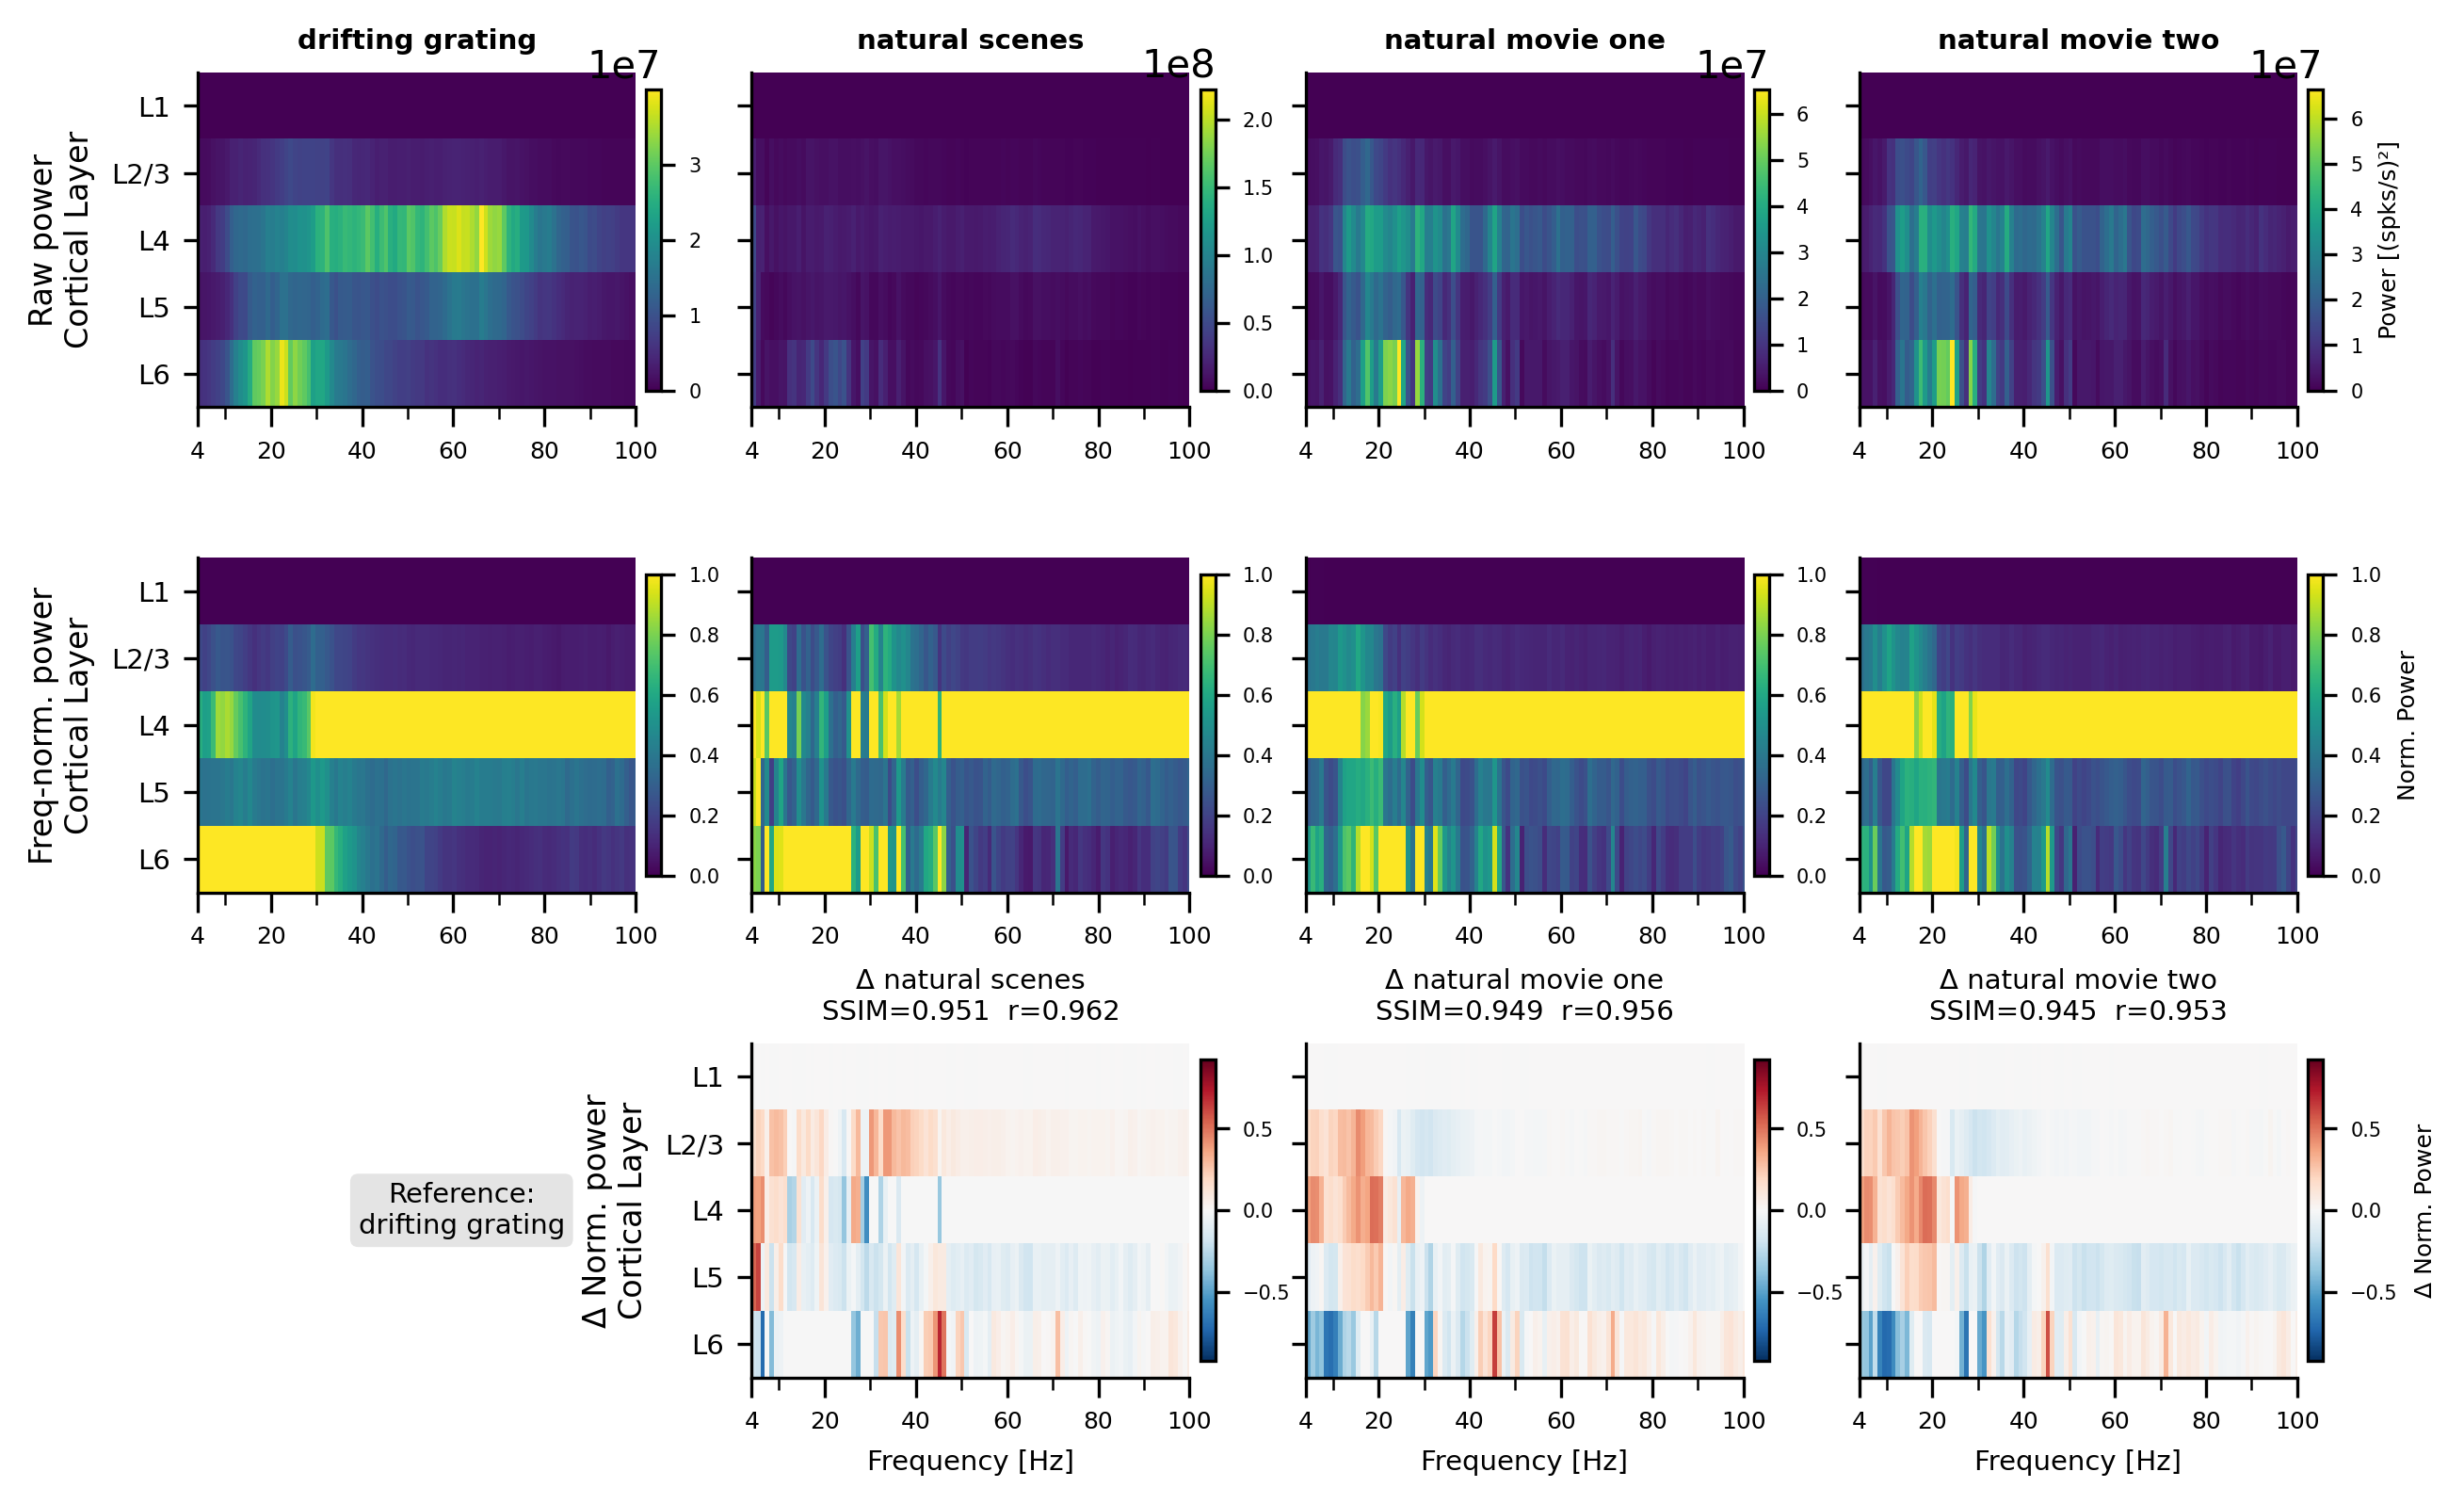

In [14]:

# ── Merged figure: raw power / freq-normalised / difference maps ─────────────
# Row 0: raw power          (4 conditions, individual vmaxes)
# Row 1: freq-norm. power   (4 conditions, shared vmin=0 vmax=1)
# Row 2: difference maps    (natural − drifting grating; col 0 = reference label)

ref_cond     = 'drifting grating'
compare_conds = ['natural scenes', 'natural movie one', 'natural movie two']
extent        = [f_ref[1], f_ref[-1], len(layers_all), 0]

fig_m, axes_m = plt.subplots(nrows=3, ncols=4, figsize=(10, 6), dpi=300,
                              gridspec_kw={"hspace": 0.45, "wspace": 0.05})
fig_m.patch.set_facecolor("none")

def _style_ax(ax, jj, row_label=None):
    ax.set_xlim([4, 100])
    ax.set_xticks([4, 20, 40, 60, 80, 100])
    ax.set_xticklabels([4, 20, 40, 60, 80, 100], fontsize=6)
    ax.set_xticks([10, 30, 50, 70, 90], minor=True)
    ax.tick_params(axis='x', which='major', length=5)
    ax.tick_params(axis='x', which='minor', length=3)
    ax.set_yticks(np.arange(len(layers_all)) + 0.5)
    ax.set_yticklabels(layers_all if jj == 0 else [], fontsize=7)
    if jj == 0 and row_label:
        ax.set_ylabel(row_label, fontsize=8)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

# ── Row 0: raw power ──────────────────────────────────────────────────────────
for jj, cond in enumerate(stim_conditions):
    ax = axes_m[0, jj]
    pm = power_matrices[cond]
    im = ax.imshow(pm, aspect="auto", origin="upper", extent=extent,
                   cmap="viridis", vmin=0, vmax=np.max(pm))
    _style_ax(ax, jj, "Raw power\nCortical Layer")
    ax.set_title(cond, fontsize=7, fontweight="bold")
    cbar = fig_m.colorbar(im, ax=ax, shrink=0.9, pad=0.02)
    cbar.ax.tick_params(labelsize=5)
    cbar.ax.yaxis.set_offset_position("right")
    if jj == 3:
        cbar.set_label("Power [(spks/s)²]", fontsize=6)

# ── Row 1: freq-normalised power ─────────────────────────────────────────────
for jj, cond in enumerate(stim_conditions):
    ax = axes_m[1, jj]
    pm_norm = power_matrices_norm[cond]
    im = ax.imshow(pm_norm, aspect="auto", origin="upper", extent=extent,
                   cmap="viridis", vmin=0, vmax=1)
    _style_ax(ax, jj, "Freq-norm. power\nCortical Layer")
    cbar = fig_m.colorbar(im, ax=ax, shrink=0.9, pad=0.02)
    cbar.ax.tick_params(labelsize=5)
    cbar.ax.yaxis.set_offset_position("right")
    if jj == 3:
        cbar.set_label("Norm. Power", fontsize=6)

# ── Row 2: difference maps ────────────────────────────────────────────────────
ref_img  = power_matrices_norm[ref_cond]
diff_max = max(np.abs(power_matrices_norm[c] - ref_img).max() for c in compare_conds)

# Col 0: reference label panel
axes_m[2, 0].axis("off")
axes_m[2, 0].text(0.5, 0.5, f"Reference:\n{ref_cond}", ha="center", va="center",
                   fontsize=7, transform=axes_m[2, 0].transAxes,
                   bbox=dict(boxstyle="round,pad=0.3", facecolor="lightgray",
                             edgecolor="none", alpha=0.6))

for jj, cond in enumerate(compare_conds):
    ax = axes_m[2, jj + 1]
    diff = power_matrices_norm[cond] - ref_img
    im = ax.imshow(diff, aspect="auto", origin="upper", extent=extent,
                   cmap="RdBu_r", vmin=-diff_max, vmax=diff_max)
    _style_ax(ax, jj, "Δ Norm. power\nCortical Layer")  # jj=0 → col 1 has no label
    s_val = img_metrics[cond]["ssim"]
    r_val = img_metrics[cond]["pearsonr"]
    ax.set_title(f"Δ {cond}\nSSIM={s_val:.3f}  r={r_val:.3f}", fontsize=7)
    ax.set_xlabel("Frequency [Hz]", fontsize=7)
    cbar = fig_m.colorbar(im, ax=ax, shrink=0.9, pad=0.02)
    cbar.ax.tick_params(labelsize=5)
    cbar.ax.yaxis.set_offset_position("right")
    if jj == 2:
        cbar.set_label("Δ Norm. Power", fontsize=6)

fig_m.savefig(
    "paper_figs/fig2C_laminar_power_merged_Jun16_2026.pdf",
    dpi=300, bbox_inches="tight", transparent=True,
)


Permutation test  (N=1000 permutations)
H0: trial spectra are exchangeable between conditions
p = fraction(null <= real)  →  small p = significantly more different than chance

Condition                   real SSIM   null med   p (SSIM)   real r   null med    p (r)
--------------------------------------------------------------------------------
natural scenes                 0.9513     0.9909     0.0000   0.9624     0.9939   0.0000
natural movie one              0.9485     0.9903     0.0000   0.9561     0.9932   0.0000
natural movie two              0.9454     0.9910     0.0000   0.9529     0.9936   0.0000


/tmp/ipykernel_3745569/1284451409.py:108: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig_boot.tight_layout()


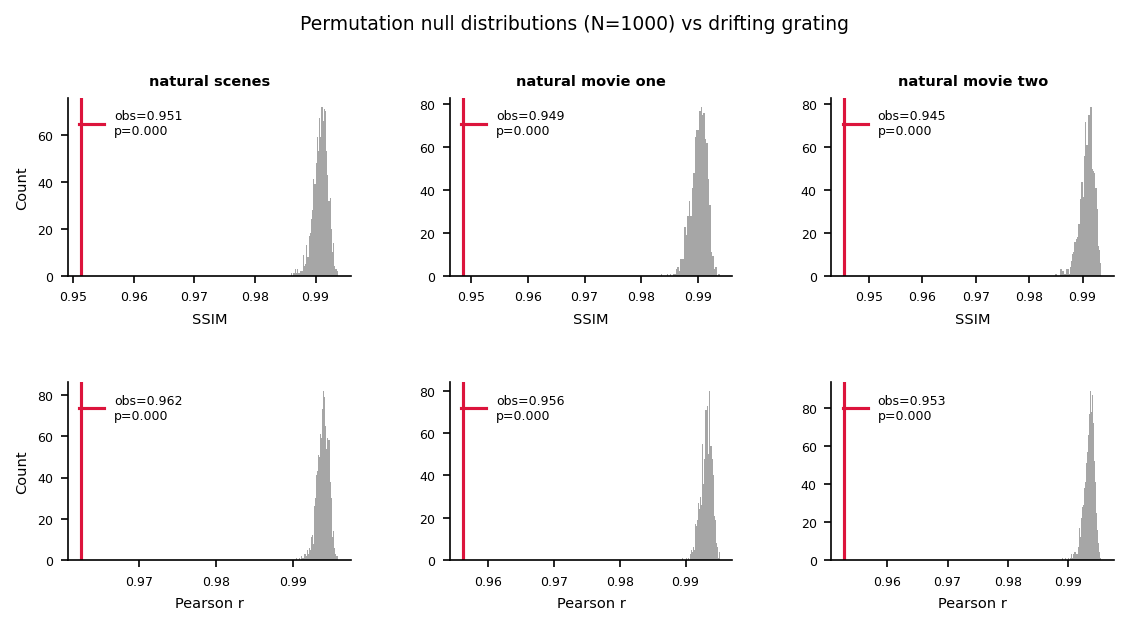

In [15]:
from skimage.metrics import structural_similarity as ssim

N_BOOT = 1000
rng = np.random.default_rng(42)

ref_cond = 'drifting grating'
compare_conds = ['natural scenes', 'natural movie one', 'natural movie two']
n_freq = power_matrices_norm[ref_cond].shape[1]  # frequencies without DC

# Pre-extract trial arrays once (avoids repeated DataFrame queries inside the loop)
# Each entry: (n_trials, n_freq_with_DC)
trial_arrays = {}
for cond in [ref_cond] + compare_conds:
    for layer in layers_all:
        row = power_layers_df.query(f'condition == "{cond}" & layer == "{layer}"')
        if len(row) > 0:
            trial_arrays[(cond, layer)] = np.array(row['power'].iloc[0])

# ── Permutation test ─────────────────────────────────────────────────────────
# Logic: pool trials from both conditions, randomly relabel → build null
# distribution of SSIM/r when there is NO real difference.
# Under H0 (exchangeable trials): each group's mean ≈ the grand mean → null SSIM near 1.
# If real SSIM << null SSIM, the maps are genuinely more different than chance.
# p-value = fraction(null <= real)  → small p means significantly different.

boot_results = {}
for cond in compare_conds:
    boot_ssim = np.zeros(N_BOOT)
    boot_r    = np.zeros(N_BOOT)
    for b in range(N_BOOT):
        pm_A = np.zeros((len(layers_all), n_freq))
        pm_B = np.zeros((len(layers_all), n_freq))
        for i, layer in enumerate(layers_all):
            t_ref = trial_arrays.get((ref_cond, layer))
            t_cmp = trial_arrays.get((cond, layer))
            if t_ref is None or t_cmp is None:
                continue
            n_ref  = len(t_ref)
            pooled = np.vstack([t_ref, t_cmp])           # (n_ref+n_cmp, n_freq_dc)
            idx    = rng.permutation(len(pooled))
            pm_A[i] = pooled[idx[:n_ref],  1:].mean(axis=0)   # skip DC
            pm_B[i] = pooled[idx[n_ref:],  1:].mean(axis=0)
        max_A = np.max(pm_A, axis=0); max_A[max_A == 0] = 1
        max_B = np.max(pm_B, axis=0); max_B[max_B == 0] = 1
        norm_A = pm_A / max_A
        norm_B = pm_B / max_B
        boot_ssim[b] = ssim(norm_A, norm_B, data_range=1.0, win_size=3)
        boot_r[b]    = pearsonr(norm_A.flatten(), norm_B.flatten())[0]
    boot_results[cond] = {'ssim': boot_ssim, 'r': boot_r}

# ── Print summary ─────────────────────────────────────────────────────────────
print(f"Permutation test  (N={N_BOOT} permutations)")
print("H0: trial spectra are exchangeable between conditions")
print("p = fraction(null <= real)  →  small p = significantly more different than chance\n")
print(f"{'Condition':<25}  {'real SSIM':>10}  {'null med':>9}  {'p (SSIM)':>9}  "
      f"{'real r':>7}  {'null med':>9}  {'p (r)':>7}")
print("-" * 80)
for cond in compare_conds:
    real_ssim = img_metrics[cond]['ssim']
    real_r    = img_metrics[cond]['pearsonr']
    null_ssim = boot_results[cond]['ssim']
    null_r    = boot_results[cond]['r']
    p_ssim = np.mean(null_ssim <= real_ssim)
    p_r    = np.mean(null_r    <= real_r)
    print(f"{cond:<25}  {real_ssim:>10.4f}  {np.median(null_ssim):>9.4f}  {p_ssim:>9.4f}  "
          f"{real_r:>7.4f}  {np.median(null_r):>9.4f}  {p_r:>7.4f}")

# ── Plot null distributions ──────────────────────────────────────────────────
fig_boot, axes_boot = plt.subplots(2, len(compare_conds), figsize=(9, 4), dpi=150,
                                   gridspec_kw={'hspace': 0.6, 'wspace': 0.35})
fig_boot.patch.set_facecolor("none")
fig_boot.suptitle(f"Permutation null distributions (N={N_BOOT}) vs drifting grating",
                  fontsize=9, y=1.02)

for jj, cond in enumerate(compare_conds):
    real_ssim = img_metrics[cond]['ssim']
    real_r    = img_metrics[cond]['pearsonr']
    null_ssim = boot_results[cond]['ssim']
    null_r    = boot_results[cond]['r']
    p_ssim    = np.mean(null_ssim <= real_ssim)
    p_r       = np.mean(null_r    <= real_r)

    # Row 0: SSIM
    ax_s = axes_boot[0, jj]
    ax_s.hist(null_ssim, bins=40, color='gray', alpha=0.7, edgecolor='none')
    ax_s.axvline(real_ssim, color='crimson', linewidth=1.5,
                 label=f'obs={real_ssim:.3f}\np={p_ssim:.3f}')
    ax_s.set_title(cond, fontsize=7, fontweight='bold')
    ax_s.set_xlabel("SSIM", fontsize=7)
    if jj == 0:
        ax_s.set_ylabel("Count", fontsize=7)
    ax_s.tick_params(labelsize=6)
    ax_s.legend(fontsize=6, frameon=False, loc='upper left')
    sns.despine(ax=ax_s)

    # Row 1: Pearson r
    ax_r = axes_boot[1, jj]
    ax_r.hist(null_r, bins=40, color='gray', alpha=0.7, edgecolor='none')
    ax_r.axvline(real_r, color='crimson', linewidth=1.5,
                 label=f'obs={real_r:.3f}\np={p_r:.3f}')
    ax_r.set_xlabel("Pearson r", fontsize=7)
    if jj == 0:
        ax_r.set_ylabel("Count", fontsize=7)
    ax_r.tick_params(labelsize=6)
    ax_r.legend(fontsize=6, frameon=False, loc='upper left')
    sns.despine(ax=ax_r)

fig_boot.tight_layout()
fig_boot.savefig(
    "paper_figs/fig2C_power_permutation_test_Jun16_2026.pdf",
    dpi=300, bbox_inches="tight", transparent=True,
)
